In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import detrend
import os
#from statsmodels.tsa.tsatools import detrend

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
path="/mnt/c/Users/isabe/OneDrive/Desktop/Lavoro/Tuscia/chiara/peaks_background/bufale_isa/"
os.chdir(path)

In [4]:
file_path_CH4 = './dati_bufale/dati_grezzi_agosto_luglio/Dataset_CH4/Bufale_Rinna/Luglio/Dati_moologger/Amaseno Luglio 2024-07012024115100-07312024115100.csv'

# Caricamento dei dati dai file
df = pd.read_csv(file_path_CH4, usecols = ["timestamp", "CH4", "CH4-mgm3" , "CO2", "CO2-mgm3"], skiprows=1)

print(df.head())

# Replace 'N.A' with np.nan
df['CH4'] = df['CH4'].replace('N.A', np.nan)
df_clean = df.dropna(subset=['CH4'])

df_clean['CH4'] = pd.to_numeric(df_clean['CH4'])

df = df_clean

print(df.head())

ch4 = df_clean[['CH4','timestamp']]

#df.to_csv('./dati_bufale/Settimana1-BUFALE-clean.csv', index=False)




/tmp/ipykernel_513/2112700799.py:4: DtypeWarning: Columns (1,2,3,4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path_CH4, usecols = ["timestamp", "CH4", "CH4-mgm3" , "CO2", "CO2-mgm3"], skiprows=1)


                    timestamp    CH4 CH4-mgm3    CO2  CO2-mgm3
0  07/01/2024 09:51:00.024698  195.8  128.452  645.1  1161.186
1  07/01/2024 09:51:01.026654  185.2  121.498  627.0  1128.606
2  07/01/2024 09:51:02.029196  195.8  128.452  602.3  1084.145
3  07/01/2024 09:51:03.032440  188.8   123.86  605.6  1090.085
4  07/01/2024 09:51:04.035013  191.8  125.828  611.2  1100.166
                    timestamp    CH4 CH4-mgm3    CO2  CO2-mgm3
0  07/01/2024 09:51:00.024698  195.8  128.452  645.1  1161.186
1  07/01/2024 09:51:01.026654  185.2  121.498  627.0  1128.606
2  07/01/2024 09:51:02.029196  195.8  128.452  602.3  1084.145
3  07/01/2024 09:51:03.032440  188.8   123.86  605.6  1090.085
4  07/01/2024 09:51:04.035013  191.8  125.828  611.2  1100.166


/tmp/ipykernel_513/2112700799.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['CH4'] = pd.to_numeric(df_clean['CH4'])


In [5]:
ch4.head()
print(df.tail())

                          timestamp   CH4  CH4-mgm3    CO2  CO2-mgm3
2212335  2024-08-30 08:20:42.685681  91.3    59.896  969.1  1741.869
2212336  2024-08-30 08:20:43.688536  82.9    54.385  929.1  1672.388
2212337  2024-08-30 08:20:44.691011  75.1    49.268  873.3  1571.948
2212338  2024-08-30 08:20:45.693816  71.0    46.579  836.3  1505.348
2212339  2024-08-30 08:20:46.695530  64.4    42.249  819.5  1475.107


Average CH4 data: 126.96972088574533


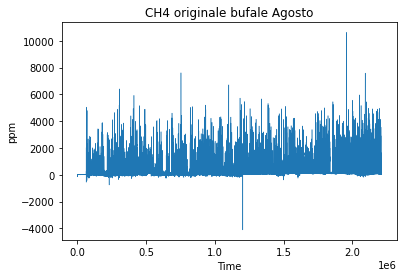

In [7]:
#calcolo media della serie originale di ch4
average_ch4 = np.mean(df['CH4'])
print("Average CH4 data:", average_ch4)

plt.figure(facecolor='white')
plt.xlabel('Time')
plt.ylabel('ppm')
plt.title('CH4 originale bufale Agosto')

#plt.plot(ch4['timestamp'], ch4['CH4'], marker = ".",linewidth=0.5)
plt.plot(df['CH4'], linewidth=0.5, label='Original CH4 series')

# Format the x-axis to show day and month
#plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d-%b'))

plt.savefig('./dati_bufale/dati_grezzi_agosto_luglio/Dataset_CH4/Bufale_Rinna/Agosto/protocollo_1/plot_bufale/CH4_originale_bufale.png', dpi=250, format="png")

Average CH4 detrended linear: -6.722897669978968e-14


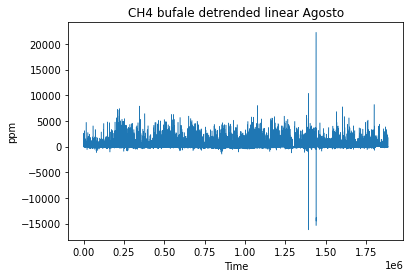

In [5]:
#++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
#Detrending With A Linear Model (scipy)
ch4_detrended = pd.DataFrame(df)
ch4_detrended['CH4'] = detrend(df['CH4'], type='linear')

#calcolo media
average_det_lin = np.mean(ch4_detrended['CH4'])
print("Average CH4 detrended linear:", average_det_lin)

plt.figure(facecolor='white')
plt.xlabel('Time')
plt.ylabel('ppm')
plt.title('CH4 bufale detrended linear Agosto')
plt.plot(ch4_detrended['CH4'],linewidth=0.5,label='Detrended linear')
#plt.legend()

#plt.savefig('./dati_bufale/dati_grezzi_agosto_luglio/Dataset_CH4/Bufale_Rinna/Agosto/protocollo_1/plot_bufale/ch4_detrended_linear.png', dpi=200, format="png")
ch4_detrended.to_csv('./dati_bufale/dati_grezzi_agosto_luglio/Dataset_CH4/Bufale_Rinna/Luglio/protocollo_1/ch4_moologger_detrended_linear.csv', index=False)


In [6]:
ch4_detrended.tail(10)

,timestamp,CH4,CH4-mgm3,CO2,CO2-mgm3
1886863,07/23/2024 12:44:53.221190,-2.860602,-72.033,1028.3,1850.949
1886864,07/23/2024 12:44:54.223394,-4.160472,-72.886,907.1,1632.788
1886865,07/23/2024 12:44:55.225930,-3.060341,-72.164,848.0,1526.408
1886866,07/23/2024 12:44:56.229238,-8.360211,-75.641,810.1,1458.187
1886867,07/23/2024 12:44:57.232390,-11.460081,-77.806,785.2,1413.367
1886868,07/23/2024 12:44:58.235216,0.840050,-69.605,751.7,1349.467
1886869,07/23/2024 12:44:59.237076,-10.359820,-76.953,711.5,1280.706
1886870,07/23/2024 12:45:00.238828,-13.759690,-79.184,729.3,1312.747
1886871,07/23/2024 12:45:01.241485,-17.059559,-81.348,755.8,1360.447
1886872,07/23/2024 12:45:02.244261,-18.459429,-82.267,729.2,1312.567


In [ ]:

#++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
#Detrending With A Quadratic Model (statsmodels)
detrended_quadratic = pd.DataFrame(df)
detrended_quadratic['CH4'] = detrend(df['CH4'], order=2)

print(detrended_quadratic.head())

#calcolo media
average_det_quad = np.mean(detrended_quadratic['CH4'])
print("Average CH4 detrended quadratic:", average_det_quad)

plt.xlabel('Time')
plt.ylabel('ppm')
plt.title('Comparison CH4 pascolo detrended quadratic')
plt.plot(detrended_quadratic['CH4'],linewidth=0.5,label='Detrended quadratic')

plt.legend()

plt.savefig('./plot_bufale/CH4_detrended_quadratic_bufale.pdf', dpi=400, format="pdf")

detrended_quadratic.to_csv('./dati_bufale/ch4_detrended_quadratic_bufale.csv', index=False)


#++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++



In [ ]:
#TODO: to try with only ch4 not with dataframe

In [45]:
#++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
#Detrending With A Moving Average Model
rolling_mean = ch4['CH4'].rolling(window=60, center=True).mean()
detrended_moving = ch4['CH4'] - rolling_mean

print(rolling_mean.head())
'''
#calcolo media
average_det_mov = np.mean(detrended_moving)
print("Average CH4 detrended moving model:", average_det_mov)

plt.xlabel('Time')
plt.ylabel('ppm')
plt.title('Comparison CH4 pascolo detrended moving model')
plt.plot(detrended_moving,linewidth=0.5,label='Detrended moving model' )

plt.legend()

plt.savefig('C:/Users/chiar/OneDrive/Desktop/PROVE/PROVE MAGGIO/Profili/CH4/detrend_CH4/comparison_CH4_detrended_moving_model.pdf', dpi=400, format="pdf")

'''

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: CH4, dtype: float64


'\n#calcolo media\naverage_det_mov = np.mean(detrended_moving)\nprint("Average CH4 detrended moving model:", average_det_mov)\n\nplt.xlabel(\'Time\')\nplt.ylabel(\'ppm\')\nplt.title(\'Comparison CH4 pascolo detrended moving model\')\nplt.plot(detrended_moving,linewidth=0.5,label=\'Detrended moving model\' )\n\nplt.legend()\n\nplt.savefig(\'C:/Users/chiar/OneDrive/Desktop/PROVE/PROVE MAGGIO/Profili/CH4/detrend_CH4/comparison_CH4_detrended_moving_model.pdf\', dpi=400, format="pdf")\n\n'